In [83]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt





In [84]:
import io
import os
import unicodedata
import string
import glob

import torch
import random

# alphabet small + capital letters + " .,;'"
ALL_LETTERS = string.ascii_letters + " .,;'"
N_LETTERS = len(ALL_LETTERS)

# Turn a Unicode string to plain ASCII, thanks to https://stackoverflow.com/a/518232/2809427
def unicode_to_ascii(s):
    return ''.join(
        c for c in unicodedata.normalize('NFD', s)
        if unicodedata.category(c) != 'Mn'
        and c in ALL_LETTERS
    )

def load_data():
    category_lines = {}
    all_categories = []

    def read_lines(filename):
        with open(filename, encoding='utf-8') as f:
            lines = f.read().strip().split('\n')
        return [unicode_to_ascii(line) for line in lines]

    for filename in glob.glob('/content/Names/*.txt'):
        category = os.path.splitext(os.path.basename(filename))[0]
        all_categories.append(category)

        lines = read_lines(filename)
        category_lines[category] = lines

    return category_lines, all_categories


"""
To represent a single letter, we use a “one-hot vector” of
size <1 x n_letters>. A one-hot vector is filled with 0s
except for a 1 at index of the current letter, e.g. "b" = <0 1 0 0 0 ...>.

To make a word we join a bunch of those into a
2D matrix <line_length x 1 x n_letters>.

That extra 1 dimension is because PyTorch assumes
everything is in batches - we’re just using a batch size of 1 here.
"""

# Find letter index from all_letters, e.g. "a" = 0
def letter_to_index(letter):
    return ALL_LETTERS.find(letter)

# Just for demonstration, turn a letter into a <1 x n_letters> Tensor
def letter_to_tensor(letter):
    tensor = torch.zeros(1, N_LETTERS)
    tensor[0][letter_to_index(letter)] = 1
    return tensor

# Turn a line into a <line_length x 1 x n_letters>,
# or an array of one-hot letter vectors
def line_to_tensor(line):
    tensor = torch.zeros(len(line), 1, N_LETTERS)
    for i, letter in enumerate(line):
        tensor[i][0][letter_to_index(letter)] = 1
    return tensor


def random_training_example(category_lines, all_categories):

    def random_choice(a):
        random_idx = random.randint(0, len(a) - 1)
        return a[random_idx]

    category = random_choice(all_categories)
    line = random_choice(category_lines[category])
    category_tensor = torch.tensor([all_categories.index(category)], dtype=torch.long)
    line_tensor = line_to_tensor(line)
    return category, line, category_tensor, line_tensor



if __name__ == '__main__':
    print(ALL_LETTERS)
    print(unicode_to_ascii('Ślusàrski'))

    category_lines, all_categories = load_data()
    print(category_lines['Italian'][:5])

    print(letter_to_tensor('J')) # [1, 57]
    print(line_to_tensor('Jones').size()) # [5, 1, 57]

abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ .,;'
Slusarski
['Abandonato', 'Abatangelo', 'Abatantuono', 'Abate', 'Abategiovanni']
tensor([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0.]])
torch.Size([5, 1, 57])


In [85]:
class RNN(nn.Module):
  def __init__(self,input_size,hidden_size,output_size):
    super().__init__()
    self.hidden_size=hidden_size
    self.i2h=nn.Linear(input_size+hidden_size,hidden_size)
    self.i2o=nn.Linear(input_size+hidden_size,output_size)
    self.softmax=nn.LogSoftmax(dim=1)


  def forward(self,input_tensor,hidden_tensor) :
    combined=torch.cat((input_tensor,hidden_tensor),dim=1)
    hidden_tensor=self.i2h(combined)
    output_tensor=self.i2o(combined)
    output_tensor=self.softmax(output_tensor)
    return output_tensor,hidden_tensor
  def init_hidden(self):
        return torch.zeros(1, self.hidden_size)




In [86]:
category_lines, all_categories = load_data()
n_categories = len(all_categories)

n_hidden = 128


In [87]:
n_categories,all_categories

(18,
 ['Japanese',
  'Portuguese',
  'Czech',
  'Irish',
  'Polish',
  'Vietnamese',
  'Chinese',
  'German',
  'Italian',
  'Scottish',
  'Korean',
  'Greek',
  'Arabic',
  'Russian',
  'French',
  'Spanish',
  'English',
  'Dutch'])

In [88]:
def category_from_output(output):
    category_idx = torch.argmax(output).item()
    return all_categories[category_idx]

In [89]:
rnn = RNN(N_LETTERS, n_hidden, n_categories)
Loss=nn.NLLLoss()


In [90]:
optim=torch.optim.SGD(rnn.parameters(),lr=0.005)


In [91]:
def train(line_tensor,category_tensor):
  hidden=rnn.init_hidden()
  for i in range(line_tensor.size()[0]):
    output,hidden_tensor=rnn(line_tensor[i],hidden)
  loss=Loss(output,category_tensor)
  loss.backward()
  optim.step()
  optim.zero_grad()
  return output, loss.item()



In [92]:
current_loss = 0
all_losses = []
plot_steps, print_steps = 1000, 5000
n_iters = 300000
for i in range(n_iters):
    category, line, category_tensor, line_tensor = random_training_example(category_lines, all_categories)

    output, loss = train(line_tensor, category_tensor)
    current_loss += loss

    if (i+1) % plot_steps == 0:
        all_losses.append(current_loss / plot_steps)
        current_loss = 0

    if (i+1) % print_steps == 0:
        guess = category_from_output(output)
        correct = "CORRECT" if guess == category else f"WRONG ({category})"
        print(f"{i+1} {(i+1)/n_iters*100} {loss:.4f} {line} / {guess} {correct}")


5000 1.6666666666666667 2.7349 Yeo / Portuguese WRONG (Korean)
10000 3.3333333333333335 1.5698 Petrakis / Greek CORRECT
15000 5.0 2.9967 Voneve / French WRONG (Czech)
20000 6.666666666666667 1.9692 Slusarczyk / Polish CORRECT
25000 8.333333333333332 1.9994 Simon / Irish CORRECT
30000 10.0 1.6260 Fashingbauer / German CORRECT
35000 11.666666666666666 0.9571 Rousses / Greek CORRECT
40000 13.333333333333334 2.0399 Oh  / Korean CORRECT
45000 15.0 3.2241 Schuttmann / Irish WRONG (German)
50000 16.666666666666664 2.3020 Shim / Vietnamese WRONG (Korean)
55000 18.333333333333332 2.9294 Hasimoto / Portuguese WRONG (Japanese)
60000 20.0 1.9785 Porra / Japanese WRONG (Spanish)
65000 21.666666666666668 3.0850 Gonzales / Greek WRONG (Spanish)
70000 23.333333333333332 1.6002 Husk / Polish WRONG (Czech)
75000 25.0 3.7408 Holan / Irish WRONG (Czech)
80000 26.666666666666668 2.1390 Murchadh / Vietnamese WRONG (Irish)
85000 28.333333333333332 1.0836 Antunez / Spanish CORRECT
90000 30.0 2.1196 O'Neal / C

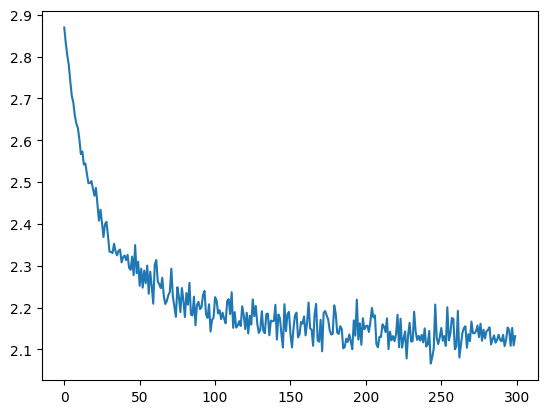

In [93]:
plt.figure()
plt.plot(all_losses)
plt.show()

In [94]:
def predict(input_line):
    print(f"\n> {input_line}")
    with torch.no_grad():
        line_tensor = line_to_tensor(input_line)

        hidden = rnn.init_hidden()

        for i in range(line_tensor.size()[0]):
            output, hidden = rnn(line_tensor[i], hidden)

        guess = category_from_output(output)
        print(guess)


In [98]:
Names=["Kamal","Kamel","Ali","Potter","Harry","Messi","Ronaldo","Salah"]
for name in Names:
  predict(name)



> Nader
German

> Kamal
Czech

> Kamel
Czech

> Ali
Italian

> Potter
German

> Harry
Irish

> Messi
Italian

> Ronaldo
Portuguese

> Salah
Vietnamese
